# Praktikum Sub-CPMK-3 &mdash; Transformasi dan Penapisan pada Domain Frekuensi

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | ................................................ |
| **NIM** | ................................................ |
| **Kelas / Kelompok** | ................................................ |
| **Tanggal praktikum** | ................................................ |

---

### Capaian yang diukur
**Sub-CPMK-3**: Mahasiswa mampu menerapkan transformasi citra pada domain frekuensi dan penapisan berbasis frekuensi.

### Rujukan utama
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 4 (§4.4&ndash;4.10). Nomor persamaan mengikuti buku tersebut.

### Petunjuk pengerjaan
1. Jalankan sel berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih tetap) &mdash; **tidak perlu mengunggah berkas**.
4. Bagian bertanda **[Pengayaan]** boleh dilewati; jalur inti selesai dalam &plusmn;120 menit.
5. Konvensi indeks: pada `np.fft.fft2(f)[u, v]`, **u mengikuti baris dan v mengikuti kolom**, sama dengan Gonzalez (x = arah baris).
6. Kumpulkan dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK3_NIM_Nama.ipynb`.

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan dan citra uji | 10 |
| 1 | DFT dari definisi dan validasinya (§4.4&ndash;4.6) | 25 |
| 2 | Spektrum, sifat translasi, dan peran fase (§4.6) | 15 |
| 3 | Penapisan lolos-rendah: delapan langkah, pelapis, riak, derau (§4.7&ndash;4.8) | 35 |
| 4 | Lolos-tinggi, penekanan frekuensi tinggi, kesetaraan spasial&ndash;frekuensi (§4.9) | 25 |
| 5 | Studi kasus: derau periodik pada citra perairan (§4.10) | 15 |
| 6 | Pemeriksaan akhir dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Jalankan sel berikut **tanpa diubah**.

NumPy 2.5.4 | OpenCV 5.0.0
kisi               (256, 256) min 38 maks 218
kotak              (256, 256) min 0 maks 255
bersih             (256, 256) min 6 maks 252
berderau           (256, 256) min 0 maks 255
perairan           (240, 360) min 103 maks 196
perairan_bergaris  (240, 360) min 84 maks 217


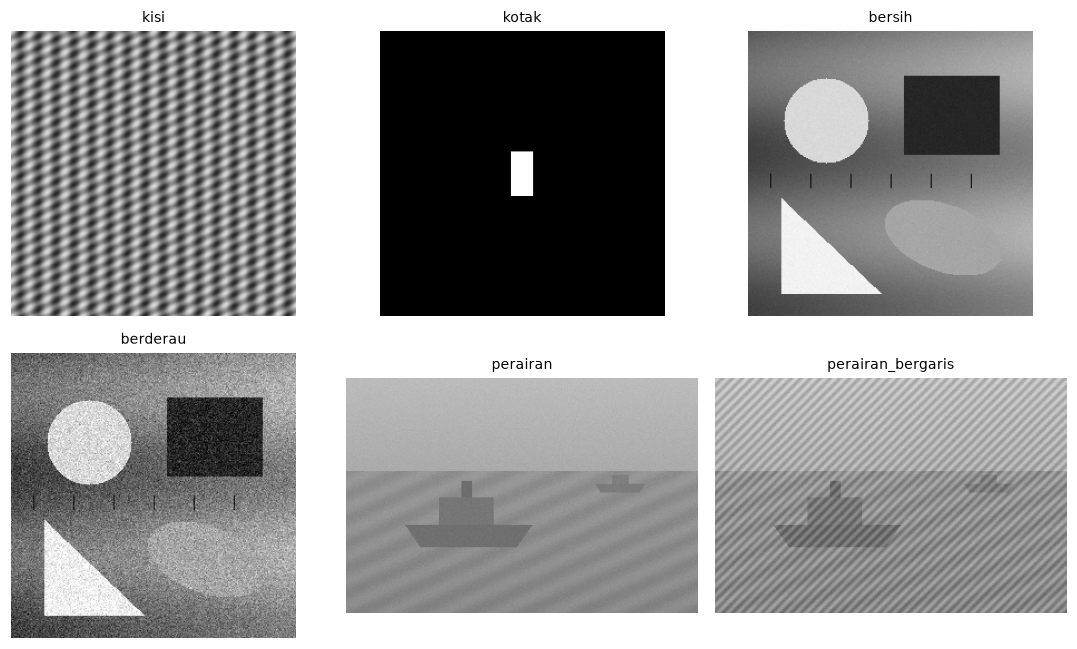

In [1]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis Sub-CPMK-3 (benih acak tetap, hanya NumPy).

Hanya memakai NumPy agar citra identik di versi OpenCV mana pun. Bebas lisensi dan reprodusibel.
"""
import numpy as np

BENIH = 2027


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _adegan(rng, h=256, w=256):
    """Adegan dasar: gradasi, lingkaran, persegi, elips, segitiga, garis halus (float 0..1)."""
    yy, xx = _grid(h, w)
    img = 0.35 + 0.25 * (xx / w) + 0.10 * np.sin(yy / 23.0)
    img[(xx - 70) ** 2 + (yy - 80) ** 2 <= 38 ** 2] = 0.85
    img[(yy >= 40) & (yy <= 110) & (xx >= 140) & (xx <= 225)] = 0.15
    u, v = xx - 175, yy - 185
    t = np.deg2rad(20)
    ue, ve = u * np.cos(t) + v * np.sin(t), -u * np.sin(t) + v * np.cos(t)
    img[(ue / 55) ** 2 + (ve / 30) ** 2 <= 1] = 0.65
    img[(yy >= 150) & (yy <= 235) & (xx >= 30) & (xx <= 30 + (yy - 150) * 1.05)] = 0.95
    for i in range(6):
        img[128:141, 20 + 36 * i] = 0.05
    img += rng.normal(0, 0.01, img.shape)
    return np.clip(img, 0, 1)


def kisi(h=256, w=256):
    """Dua pola periodik: garis tegak (16 siklus melintang kolom) dan garis miring (u0, v0) = (24, 12)."""
    yy, xx = _grid(h, w)
    g = 128 + 50 * np.cos(2 * np.pi * 16 * xx / w) + 40 * np.cos(2 * np.pi * (24 * yy / h + 12 * xx / w))
    return np.clip(np.floor(g + 0.5), 0, 255).astype(np.uint8)


def kotak(h=256, w=256):
    """Persegi panjang putih di tengah latar hitam (bertepi tajam)."""
    img = np.zeros((h, w), np.uint8)
    img[h // 2 - 20:h // 2 + 20, w // 2 - 10:w // 2 + 10] = 255
    return img


def bersih(rng):
    return np.clip(np.floor(255 * _adegan(rng) + 0.5), 0, 255).astype(np.uint8)


def beri_derau_gauss(img, rng, sigma=20.0):
    return np.clip(np.floor(img.astype(np.float64) + rng.normal(0, sigma, img.shape) + 0.5), 0, 255).astype(np.uint8)


def beri_derau_periodik(img, amp=28.0, u0=12, v0=40):
    """Interferensi sinusoidal: komponen pada (u0, v0) dan (−u0, −v0) dalam indeks DFT (baris, kolom)."""
    h, w = img.shape
    yy, xx = _grid(h, w)
    g = img.astype(np.float64) + amp * np.sin(2 * np.pi * (u0 * yy / h + v0 * xx / w))
    return np.clip(np.floor(g + 0.5), 0, 255).astype(np.uint8)


def perairan(rng, h=240, w=360):
    """Langit, laut, dua kapal, kabut, derau sensor."""
    yy, xx = _grid(h, w)
    cak = 95
    img = np.where(yy < cak, 0.78 - 0.15 * (yy / cak),
                   0.42 + 0.06 * np.sin(xx / 9.0 + yy / 4.0) - 0.10 * ((yy - cak) / (h - cak)))
    img[(yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)] = 0.12
    img[(yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)] = 0.18
    img[(yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)] = 0.10
    img[(yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)] = 0.22
    img[(yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)] = 0.25
    img = 0.45 * img + 0.55 * 0.70
    img += rng.normal(0, 0.010, img.shape)
    return np.clip(np.floor(255 * img + 0.5), 0, 255).astype(np.uint8)


def masker_perairan(h=240, w=360):
    """Masker kebenaran dasar (kapal, laut)."""
    yy, xx = _grid(h, w)
    kapal = np.zeros((h, w), bool)
    kapal |= (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    kapal |= (yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)
    kapal |= (yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)
    kapal |= (yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)
    kapal |= (yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)
    sekitar = np.zeros_like(kapal)
    sekitar[95:185, 45:205] = True
    sekitar[92:125, 245:315] = True
    laut = (yy >= 100) & ~sekitar
    return kapal, laut


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    b = bersih(rng)
    bg = beri_derau_gauss(b, rng)
    air = perairan(rng)
    return {"kisi": kisi(), "kotak": kotak(), "bersih": b, "berderau": bg,
            "perairan": air, "perairan_bergaris": beri_derau_periodik(air, amp=22.0, u0=24, v0=36)}

def tampil(daftar, judul=None, kolom=None, tinggi=3.0, skala=True):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.4 * kolom, tinggi * baris)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap='gray', **({'vmin': 0, 'vmax': 255} if skala else {})); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def spektrum_log(f):
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(f.astype(np.float64)))))
    return (255 * S / S.max()).astype(np.uint8)

def psnr(acuan, uji):
    mse = np.mean((acuan.astype(float) - uji.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

C = bangkitkan_semua()
kisi_, kotak_, bersih, berderau = C['kisi'], C['kotak'], C['bersih'], C['berderau']
air, air_garis = C['perairan'], C['perairan_bergaris']
kabur = cv2.GaussianBlur(bersih, (9, 9), 1.5)   # masukan Bagian 4
for k, v in C.items(): print(f'{k:18s}', v.shape, 'min', v.min(), 'maks', v.max())
tampil(list(C.values()), list(C.keys()), kolom=3)

## Bagian 1 &mdash; DFT dari definisi (25 menit)

DFT satu variabel (Gonzalez Eq. 4-44) dan inversnya (Eq. 4-45):

$$F(u) = \sum_{x=0}^{M-1} f(x)\,e^{-j2\pi ux/M}, \qquad f(x) = \frac{1}{M}\sum_{u=0}^{M-1} F(u)\,e^{j2\pi ux/M}$$

Dalam bentuk matriks, $F = W f$ dengan $W_{ux} = e^{-j2\pi ux/M}$.

In [2]:
# TODO 1.1 — DFT dan IDFT 1D lewat matriks W. Jangan memakai np.fft di dalam fungsi.
def dft1(f):
    f = np.asarray(f, dtype=np.complex128)
    M = len(f)
    u = np.arange(M)[:, None]
    x = np.arange(M)[None, :]
    W = np.exp(-2j * np.pi * ((u * x) % M) / M)
    return W @ f

def idft1(F):
    F = np.asarray(F, dtype=np.complex128)
    M = len(F)
    x = np.arange(M)[:, None]
    u = np.arange(M)[None, :]
    W_inv = np.exp(2j * np.pi * ((x * u) % M) / M) / M
    return W_inv @ F

# Uji: contoh kuliah f = [3, 1, 2, 2]  ->  F = [8, 1+1j, 2, 1-1j]
f_contoh = np.array([3, 1, 2, 2], float)
F_contoh = dft1(f_contoh)
print('F contoh kuliah :', np.round(F_contoh, 6))
print('IDFT kembali    :', np.round(idft1(F_contoh).real, 6))

# Validasi terhadap np.fft.fft pada vektor acak panjang 64 (selisih maks harus < 1e-9)
rng_uji = np.random.default_rng(BENIH)
v64 = rng_uji.normal(size=64)
sel_dft1 = np.max(np.abs(dft1(v64) - np.fft.fft(v64)))
sel_idft1 = np.max(np.abs(idft1(dft1(v64)) - v64))
print(f'Selisih maks dft1 vs np.fft.fft  : {sel_dft1:.2e} (< 1e-9: {sel_dft1 < 1e-9})')
print(f'Selisih maks idft1(dft1(v)) vs v : {sel_idft1:.2e} (< 1e-9: {sel_idft1 < 1e-9})')


F contoh kuliah : [8.+0.j 1.+1.j 2.-0.j 1.-1.j]
IDFT kembali    : [3. 1. 2. 2.]
Selisih maks dft1 vs np.fft.fft  : 7.59e-15 (< 1e-9: True)
Selisih maks idft1(dft1(v)) vs v : 7.53e-16 (< 1e-9: True)


In [3]:
# TODO 1.2 — DFT 2D dengan sifat keterpisahan (Eq. 4-156): DFT 1D pada setiap kolom, lalu pada setiap baris.
# Bentuk matriks: F = W_M @ f @ W_N. Uji contoh 2×2 [[4, 2], [1, 1]] -> [[8, 2], [4, 2]],
# lalu validasi pada potongan kotak_[96:160, 96:160] terhadap np.fft.fft2.
def dft2(f):
    f = np.asarray(f, dtype=np.complex128)
    M, N = f.shape
    u = np.arange(M)[:, None]; x = np.arange(M)[None, :]
    y = np.arange(N)[:, None]; v = np.arange(N)[None, :]
    W_M = np.exp(-2j * np.pi * ((u * x) % M) / M)
    W_N = np.exp(-2j * np.pi * ((y * v) % N) / N)
    return W_M @ f @ W_N

contoh_2x2 = np.array([[4, 2], [1, 1]], float)
print('DFT 2x2 contoh kuliah:\n', np.round(dft2(contoh_2x2).real, 6))

potongan = kotak_[96:160, 96:160]
sel_dft2 = np.max(np.abs(dft2(potongan) - np.fft.fft2(potongan)))
print(f'Selisih maks dft2 vs np.fft.fft2 (64x64): {sel_dft2:.2e} (< 1e-9: {sel_dft2 < 1e-9})')


DFT 2x2 contoh kuliah:
 [[8. 2.]
 [4. 2.]]
Selisih maks dft2 vs np.fft.fft2 (64x64): 6.68e-11 (< 1e-9: True)


(a) F(0,0) = 8590323.00 | MN * rerata = 8590323.00 (rerata = 131.0779) | selisih = 0.00e+00
(b) Selisih maks DFT(f*(-1)^(x+y)) vs fftshift(DFT(f)) = 0.00e+00


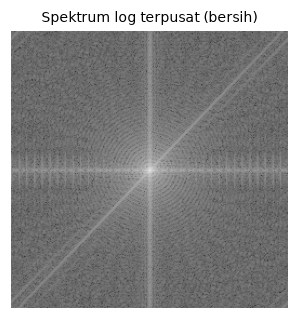

In [4]:
# TODO 1.3 — (a) Buktikan F(0,0) = MN · rerata (Eq. 4-93) pada `bersih`.
# (b) Buktikan pemusatan: DFT dari f(x,y)·(−1)^(x+y) sama dengan np.fft.fftshift(DFT f) (Eq. 4-76).
f_bersih = bersih.astype(np.float64)
M, N = f_bersih.shape
F_bersih = np.fft.fft2(f_bersih)
dc = F_bersih[0, 0].real
mn_rerata = M * N * f_bersih.mean()
print(f'(a) F(0,0) = {dc:.2f} | MN * rerata = {mn_rerata:.2f} (rerata = {f_bersih.mean():.4f}) | selisih = {abs(dc - mn_rerata):.2e}')

yy, xx = np.mgrid[0:M, 0:N]
F_geser = np.fft.fft2(f_bersih * ((-1.0) ** (xx + yy)))
F_shift = np.fft.fftshift(F_bersih)
sel_pusat = np.max(np.abs(F_geser - F_shift))
print(f'(b) Selisih maks DFT(f*(-1)^(x+y)) vs fftshift(DFT(f)) = {sel_pusat:.2e}')
tampil([spektrum_log(bersih)], ['Spektrum log terpusat (bersih)'], kolom=1)


In [5]:
# [Pengayaan] TODO 1.4 — Bandingkan waktu dft2 (matriks) dan np.fft.fft2 pada citra 256×256. Nisbahnya?
t0 = time.perf_counter(); _ = dft2(bersih); t_mat = time.perf_counter() - t0
t1 = time.perf_counter(); _ = np.fft.fft2(bersih); t_fft = time.perf_counter() - t1
print(f'Waktu dft2 (matriks) : {t_mat * 1e3:.3f} ms')
print(f'Waktu np.fft.fft2    : {t_fft * 1e3:.3f} ms')
print(f'Nisbah kecepatan     : {t_mat / t_fft:.1f}x lebih cepat dengan FFT')


Waktu dft2 (matriks) : 9.118 ms
Waktu np.fft.fft2    : 0.897 ms
Nisbah kecepatan     : 10.2x lebih cepat dengan FFT


**Analisis 1.** (a) Pada contoh [3, 1, 2, 2], mengapa F(1) dan F(3) saling konjugat? Kaitkan dengan sifat masukan bernilai nyata (Eq. 4-85). (b) Apa arti fisis F(0,0) yang Anda peroleh untuk citra `bersih`? (c) Mengapa spektrum hampir selalu ditampilkan terpusat?

*Jawaban Anda:*

**(a)** Pada contoh $f = [3, 1, 2, 2]$ ($M = 4$) yang seluruh elemennya bernilai nyata, hasil DFT adalah $F = [8,\; 1+j,\; 2,\; 1-j]$. Berdasarkan sifat simetri konjugat untuk sinyal nyata (Gonzalez Eq. 4-85), berlaku $F^*(u) = F(-u \bmod M) = F(M - u)$. Untuk $u = 1$ dan $M = 4$, diperoleh $F(3) = F(4 - 1) = F^*(1)$, sehingga $F(1) = 1 + j$ dan $F(3) = 1 - j$ saling konjugat kompleks.

**(b)** Pada citra `bersih` ($256 \times 256$), diperoleh $F(0,0) = 8.590.323{,}00$, yang sama persis dengan $MN \cdot \bar{f} = 65.536 \times 131{,}0779 = 8.590.323{,}00$ (selisih $0{,}00$). Secara fisis, $F(0,0)$ adalah komponen DC (frekuensi nol $u=0, v=0$) yang merepresentasikan jumlah seluruh intensitas piksel pada citra atau tingkat kecerahan rata-rata citra ($\bar{f} = 131{,}08$) dikalikan luas citra $MN$.

**(c)** Tanpa pemusatan, komponen DC $F(0,0)$ dan frekuensi rendah terpecah di keempat sudut matriks (di sekitar $(0,0), (0,N-1), (M-1,0), (M-1,N-1)$), sedangkan bagian tengah matriks justru berisi frekuensi tertinggi $(M/2, N/2)$. Dengan mengalikan citra dengan $(-1)^{x+y}$ sebelum DFT atau memakai `fftshift` (selisih maksimum keduanya $0{,}00$), titik asal frekuensi $(0,0)$ bergeser ke pusat bidang $(M/2, N/2)$ sehingga penyebaran energi dari frekuensi rendah ke frekuensi tinggi serta simetri konjugat dapat diamati dan dirancang penapisnya secara intuitif.


## Bagian 2 &mdash; Spektrum, translasi, dan fase (15 menit)

Empat puncak terbesar selain DC pada `kisi_`:
  Indeks DFT (  0, 240) -> koordinat bertanda (u, v) = (   0,  -16), |F| = 1637526.2
  Indeks DFT (  0,  16) -> koordinat bertanda (u, v) = (   0,   16), |F| = 1637526.2
  Indeks DFT ( 24,  12) -> koordinat bertanda (u, v) = (  24,   12), |F| = 1310213.8
  Indeks DFT (232, 244) -> koordinat bertanda (u, v) = ( -24,  -12), |F| = 1310213.8


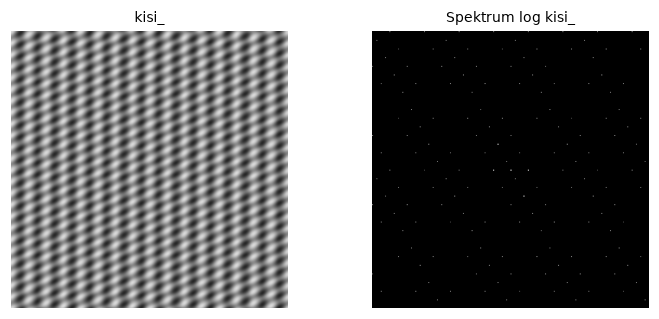

In [6]:
# TODO 2.1 — Tampilkan spektrum log `kisi_`. Cari empat puncak terbesar selain DC dan laporkan koordinatnya
# sebagai (u, v) bertanda (−128..127). Petunjuk: |F| tanpa fftshift, nolkan F[0,0], gunakan np.argsort.
M, N = kisi_.shape
F_kisi = np.abs(np.fft.fft2(kisi_.astype(np.float64)))
F_kisi[0, 0] = 0.0
idx_puncak = np.argsort(F_kisi.ravel())[::-1][:4]

print('Empat puncak terbesar selain DC pada `kisi_`:')
for i in idx_puncak:
    u, v = np.unravel_index(i, (M, N))
    u_tanda = u if u < M // 2 else u - M
    v_tanda = v if v < N // 2 else v - N
    print(f'  Indeks DFT ({u:3d}, {v:3d}) -> koordinat bertanda (u, v) = ({u_tanda:4d}, {v_tanda:4d}), |F| = {F_kisi[u, v]:.1f}')

tampil([kisi_, spektrum_log(kisi_)], ['kisi_', 'Spektrum log kisi_'], kolom=2)


Selisih maksimum magnitudo |F| : 5.82e-11
Selisih maksimum sudut fase    : 6.1850 rad


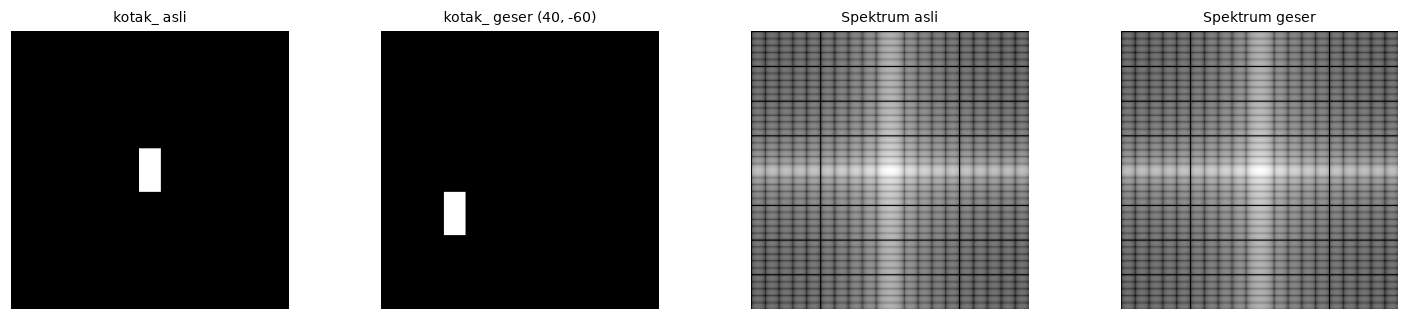

In [7]:
# TODO 2.2 — Geser `kotak_` dengan np.roll sebesar (40, −60). Buktikan |F| tidak berubah (selisih maks ≈ 0),
# tetapi fase berubah (selisih fase maks jauh dari 0). Gonzalez Eq. 4-72.
kotak_geser = np.roll(kotak_, shift=(40, -60), axis=(0, 1))
F_asli = np.fft.fft2(kotak_.astype(np.float64))
F_geser = np.fft.fft2(kotak_geser.astype(np.float64))

sel_mag = np.max(np.abs(np.abs(F_asli) - np.abs(F_geser)))
sel_fase = np.max(np.abs(np.angle(F_asli) - np.angle(F_geser)))
print(f'Selisih maksimum magnitudo |F| : {sel_mag:.2e}')
print(f'Selisih maksimum sudut fase    : {sel_fase:.4f} rad')

tampil([kotak_, kotak_geser, spektrum_log(kotak_), spektrum_log(kotak_geser)],
       ['kotak_ asli', 'kotak_ geser (40, -60)', 'Spektrum asli', 'Spektrum geser'], kolom=4)


|F_A| * exp(j*fase_B) -> korelasi dgn A = -0.0191, korelasi dgn B = +0.6246
|F_B| * exp(j*fase_A) -> korelasi dgn A = +0.6246, korelasi dgn B = -0.3369


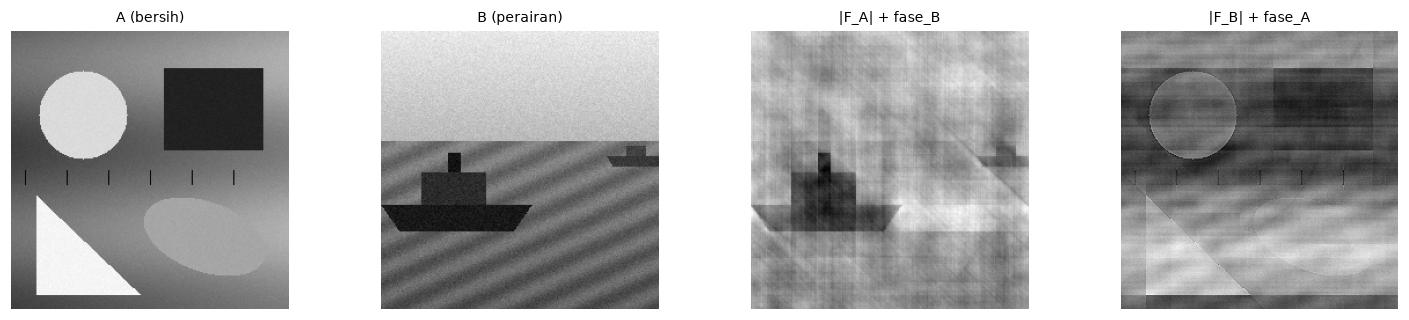

In [8]:
# TODO 2.3 — Tukar magnitudo dan fase antara A = bersih[8:248, 8:248] dan B = air[:, 60:300] (keduanya 240×240).
# Rekonstruksi |F_A|·e^{j·fase_B} dan |F_B|·e^{j·fase_A}, lalu hitung koefisien korelasi masing-masing dengan A dan B.
A = bersih[8:248, 8:248].astype(np.float64)
B = air[:, 60:300].astype(np.float64)

FA, FB = np.fft.fft2(A), np.fft.fft2(B)
rek_magA_faseB = np.fft.ifft2(np.abs(FA) * np.exp(1j * np.angle(FB))).real
rek_magB_faseA = np.fft.ifft2(np.abs(FB) * np.exp(1j * np.angle(FA))).real

r_mAfB_A = np.corrcoef(rek_magA_faseB.ravel(), A.ravel())[0, 1]
r_mAfB_B = np.corrcoef(rek_magA_faseB.ravel(), B.ravel())[0, 1]
r_mBfA_A = np.corrcoef(rek_magB_faseA.ravel(), A.ravel())[0, 1]
r_mBfA_B = np.corrcoef(rek_magB_faseA.ravel(), B.ravel())[0, 1]

print(f'|F_A| * exp(j*fase_B) -> korelasi dgn A = {r_mAfB_A:+.4f}, korelasi dgn B = {r_mAfB_B:+.4f}')
print(f'|F_B| * exp(j*fase_A) -> korelasi dgn A = {r_mBfA_A:+.4f}, korelasi dgn B = {r_mBfA_B:+.4f}')

tampil([A, B, rek_magA_faseB, rek_magB_faseA],
       ['A (bersih)', 'B (perairan)', '|F_A| + fase_B', '|F_B| + fase_A'], kolom=4, skala=False)


**Analisis 2.** (a) Kaitkan setiap puncak `kisi_` dengan pola pada citra. Mengapa garis tegak menghasilkan puncak pada sumbu v (mendatar di tampilan)? (b) Apa yang Anda simpulkan dari TODO 2.2 tentang informasi letak? (c) Dengan angka korelasi TODO 2.3, komponen mana yang membawa struktur?

*Jawaban Anda:*

**(a)** Citra `kisi_` dibentuk dari dua gelombang kosinus: komponen pertama $50\cos(2\pi \cdot 16x/W)$ (garis-garis tegak sebanyak 16 siklus melintang kolom) menghasilkan sepasang puncak konjugat pada $(u, v) = (0, 16)$ dan $(0, -16)$ dengan magnitudo $|F| = 1.637.526{,}2$; komponen kedua $40\cos(2\pi(24y/H + 12x/W))$ (garis-garis miring dengan 24 siklus arah baris dan 12 siklus arah kolom) menghasilkan pasangan puncak pada $(u, v) = (24, 12)$ dan $(-24, -12)$ dengan $|F| = 1.310.213{,}8$. Garis tegak menghasilkan puncak pada sumbu $v$ ($u = 0$) karena intensitasnya konstan sepanjang baris (arah vertikal $y$, sehingga frekuensi vertikal $u = 0$) dan hanya berosilasi sepanjang kolom (arah mendatar $x$, frekuensi $v = \pm 16$); secara umum arah vektor gelombang di ruang frekuensi tegak lurus terhadap arah tepi/garis di ruang spasial.

**(b)** Dari TODO 2.2, pergeseran melingkar `kotak_` sebesar $(x_0, y_0) = (40, -60)$ tidak mengubah spektrum magnitudo sama sekali (selisih maksimum $|F|$ sebesar $5{,}82 \times 10^{-11} \approx 0$), tetapi mengubah sudut fase secara drastis (selisih maksimum fase $6{,}1850\text{ rad}$). Sesuai teorema translasi $f(x - x_0, y - y_0) \leftrightarrow F(u, v)e^{-j2\pi(ux_0/M + vy_0/N)}$ (Eq. 4-72), magnitudo $|F(u,v)|$ bersifat invarian terhadap translasi dan hanya mencatat berapa besar energi tiap frekuensi, sedangkan **informasi letak/posisi objek sepenuhnya disimpan di dalam sudut fase**.

**(c)** Komponen yang membawa struktur dan bentuk tepi objek adalah **fase**. Terbukti pada TODO 2.3: citra rekonstruksi $|F_A|e^{j\phi_B}$ (magnitudo `bersih`, fase `perairan`) berkorelasi kuat dengan B ($r = +0{,}6246$) dan hampir tidak berkorelasi dengan A ($r = -0{,}0191$). Sebaliknya, rekonstruksi $|F_B|e^{j\phi_A}$ (magnitudo `perairan`, fase `bersih`) berkorelasi kuat dengan A ($r = +0{,}6246$) dan berkorelasi negatif dengan B ($r = -0{,}3369$). Tampilan visualnya pun selalu mengikuti citra pemilik fase.


## Bagian 3 &mdash; Penapisan lolos-rendah (35 menit)

Penapis dirancang terhadap jarak $D(u,v) = \sqrt{(u-P/2)^2 + (v-Q/2)^2}$ (Eq. 4-112):
ideal (Eq. 4-111), Butterworth $H = 1/(1+[D/D_0]^{2n})$ (Eq. 4-117), Gaussian $H = e^{-D^2/2D_0^2}$ (Eq. 4-116).

Delapan langkah Gonzalez §4.7: (1) P = 2M, Q = 2N; (2) lapisi citra; (3) kalikan $(-1)^{x+y}$; (4) DFT; (5) bangun H berukuran P&times;Q terpusat; (6) G = HF; (7) bagian nyata IDFT dikali $(-1)^{x+y}$; (8) ambil potongan M&times;N kiri atas.

In [9]:
# TODO 3.1 — Lengkapi pembangun penapis. Uji dengan D0 = 30 pada D = 30 dan D = 60:
# Butterworth n=2 -> 0,5000 dan 0,0588;  Gaussian -> 0,6065 dan 0,1353.
def jarak(P, Q):
    u, v = np.mgrid[0:P, 0:Q].astype(np.float64)
    return np.hypot(u - P / 2.0, v - Q / 2.0)

def H_ideal(P, Q, D0):
    return (jarak(P, Q) <= D0).astype(np.float64)

def H_butterworth(P, Q, D0, n=2):
    return 1.0 / (1.0 + (jarak(P, Q) / D0) ** (2 * n))

def H_gauss(P, Q, D0):
    return np.exp(-(jarak(P, Q) ** 2) / (2.0 * (D0 ** 2)))

Hb_uji = H_butterworth(200, 200, D0=30, n=2)
Hg_uji = H_gauss(200, 200, D0=30)
print(f'Butterworth n=2 (D0=30) -> D=30: {Hb_uji[100, 130]:.4f}, D=60: {Hb_uji[100, 160]:.4f}')
print(f'Gaussian        (D0=30) -> D=30: {Hg_uji[100, 130]:.4f}, D=60: {Hg_uji[100, 160]:.4f}')


Butterworth n=2 (D0=30) -> D=30: 0.5000, D=60: 0.0588
Gaussian        (D0=30) -> D=30: 0.6065, D=60: 0.1353


In [10]:
# TODO 3.2 — Implementasikan delapan langkah sebagai saring(f, H, pad), dengan pad ∈ {'constant', 'reflect', 'edge'}.
# Uji: H = 1 di mana-mana harus mengembalikan f persis (selisih maks < 1e-9).
def saring(f, H, pad='reflect'):
    M, N = f.shape
    P, Q = 2 * M, 2 * N
    fp = np.pad(f.astype(np.float64), ((0, M), (0, N)), mode=pad)
    yy, xx = np.mgrid[0:P, 0:Q]
    tanda = (-1.0) ** (xx + yy)
    F = np.fft.fft2(fp * tanda)
    G = H * F
    gp = np.fft.ifft2(G).real * tanda
    return gp[:M, :N]

sel_identitas = np.max(np.abs(saring(bersih, np.ones((512, 512))) - bersih))
print(f'Uji identitas saring (H=1) selisih maks: {sel_identitas:.2e} (< 1e-9: {sel_identitas < 1e-9})')


Uji identitas saring (H=1) selisih maks: 8.53e-14 (< 1e-9: True)


Rerata kolom 0-4 (tepi kiri):
  Citra asli          :  91.99
  (a) Tanpa pelapis   : 116.17 (selisih +24.18)
  (b) Pelapis nol     :  56.38 (selisih -35.60)
  (c) Pelapis cermin  :  92.92 (selisih +0.93)


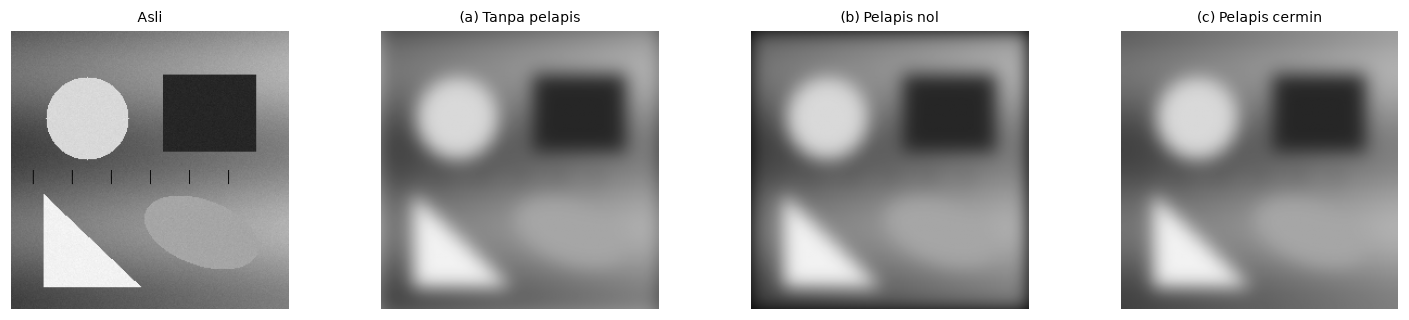

In [11]:
# TODO 3.3 — Pelapis dan wraparound. Terapkan Gaussian D0 = 10 pada `bersih` dengan tiga cara:
# (a) tanpa pelapis: H berukuran 256×256 dengan D0 = 5 (setara), pad tidak dipakai;
# (b) pelapis nol 512×512; (c) pelapis cermin 512×512.
# Laporkan rerata kolom 0–4 hasil masing-masing dan bandingkan dengan citra asli.
yy256, xx256 = np.mgrid[0:256, 0:256]
tanda256 = (-1.0) ** (xx256 + yy256)
g_tanpa = np.fft.ifft2(H_gauss(256, 256, 5) * np.fft.fft2(bersih.astype(np.float64) * tanda256)).real * tanda256
g_nol = saring(bersih, H_gauss(512, 512, 10), pad='constant')
g_cermin = saring(bersih, H_gauss(512, 512, 10), pad='reflect')

print('Rerata kolom 0-4 (tepi kiri):')
print(f'  Citra asli          : {bersih[:, :5].mean():6.2f}')
print(f'  (a) Tanpa pelapis   : {g_tanpa[:, :5].mean():6.2f} (selisih {g_tanpa[:, :5].mean() - bersih[:, :5].mean():+.2f})')
print(f'  (b) Pelapis nol     : {g_nol[:, :5].mean():6.2f} (selisih {g_nol[:, :5].mean() - bersih[:, :5].mean():+.2f})')
print(f'  (c) Pelapis cermin  : {g_cermin[:, :5].mean():6.2f} (selisih {g_cermin[:, :5].mean() - bersih[:, :5].mean():+.2f})')

tampil([bersih, g_tanpa, g_nol, g_cermin],
       ['Asli', '(a) Tanpa pelapis', '(b) Pelapis nol', '(c) Pelapis cermin'], kolom=4)


Penapis               Minimum   Maksimum
Ideal                  -35.95     301.00
Butterworth n=1         -0.00     231.71
Butterworth n=2         -8.56     267.91
Butterworth n=5        -26.24     293.20
Butterworth n=20       -35.36     300.64
Gaussian                -0.00     251.28


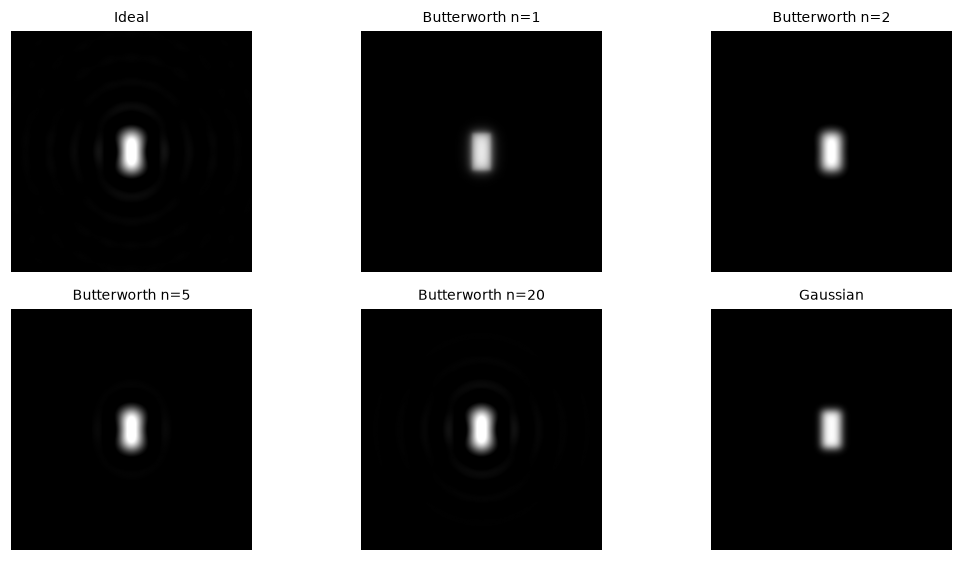

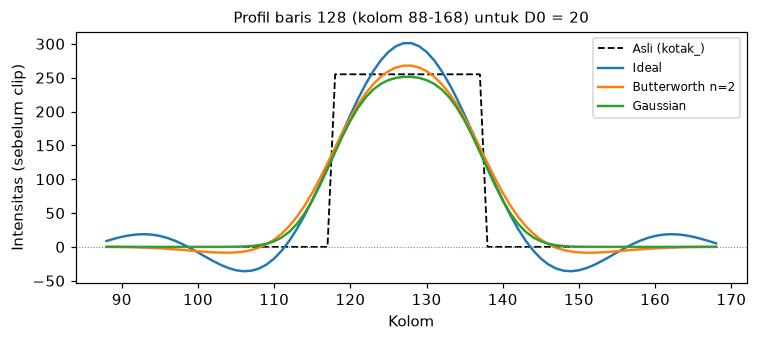

In [12]:
# TODO 3.4 — Riak (ringing). Pada `kotak_` (latar hitam, pakai pad='constant'), terapkan D0 = 20:
# ideal, Butterworth n = 1, 2, 5, 20, dan Gaussian. Laporkan nilai minimum dan maksimum hasil (sebelum clip),
# lalu gambar profil baris 128 kolom 88–168 untuk ideal, Butterworth n=2, dan Gaussian.
penapis_riak = {
    'Ideal': H_ideal(512, 512, 20),
    'Butterworth n=1': H_butterworth(512, 512, 20, n=1),
    'Butterworth n=2': H_butterworth(512, 512, 20, n=2),
    'Butterworth n=5': H_butterworth(512, 512, 20, n=5),
    'Butterworth n=20': H_butterworth(512, 512, 20, n=20),
    'Gaussian': H_gauss(512, 512, 20),
}

hasil_riak = {}
print(f'{"Penapis":18s} {"Minimum":>10s} {"Maksimum":>10s}')
for nama, H in penapis_riak.items():
    g = saring(kotak_, H, pad='constant')
    hasil_riak[nama] = g
    print(f'{nama:18s} {g.min():10.2f} {g.max():10.2f}')

tampil([np.clip(g, 0, 255) for g in hasil_riak.values()], list(hasil_riak.keys()), kolom=3, tinggi=2.6)

kol = np.arange(88, 169)
plt.figure(figsize=(7, 3.2))
plt.plot(kol, kotak_[128, 88:169], 'k--', lw=1.2, label='Asli (kotak_)')
for nama in ['Ideal', 'Butterworth n=2', 'Gaussian']:
    plt.plot(kol, hasil_riak[nama][128, 88:169], lw=1.6, label=nama)
plt.axhline(0, color='gray', lw=0.7, ls=':')
plt.title('Profil baris 128 (kolom 88-168) untuk D0 = 20', fontsize=10)
plt.xlabel('Kolom'); plt.ylabel('Intensitas (sebelum clip)'); plt.legend(fontsize=8); plt.tight_layout(); plt.show()


In [13]:
# TODO 3.5 — Reduksi derau. Pada `berderau` (derau Gaussian σ = 20), bandingkan ketiga penapis untuk
# D0 ∈ {40, 60, 80, 100, 120, 160} (pelapis cermin). Susun tabel PSNR terhadap `bersih` dan tentukan D0 terbaik tiap penapis.
daftar_D0 = [40, 60, 80, 100, 120, 160]
tabel_psnr = {'Ideal': {}, 'Butterworth n=2': {}, 'Gaussian': {}}

print(f'PSNR awal `berderau` terhadap `bersih`: {psnr(bersih, berderau):.4f} dB\n')
print(f'{"D0":>4s} {"Ideal (dB)":>12s} {"BW n=2 (dB)":>14s} {"Gaussian (dB)":>15s}')
for d0 in daftar_D0:
    gi = np.clip(np.floor(saring(berderau, H_ideal(512, 512, d0), 'reflect') + 0.5), 0, 255).astype(np.uint8)
    gb = np.clip(np.floor(saring(berderau, H_butterworth(512, 512, d0, 2), 'reflect') + 0.5), 0, 255).astype(np.uint8)
    gg = np.clip(np.floor(saring(berderau, H_gauss(512, 512, d0), 'reflect') + 0.5), 0, 255).astype(np.uint8)
    pi, pb, pg = psnr(bersih, gi), psnr(bersih, gb), psnr(bersih, gg)
    tabel_psnr['Ideal'][d0], tabel_psnr['Butterworth n=2'][d0], tabel_psnr['Gaussian'][d0] = pi, pb, pg
    print(f'{d0:4d} {pi:12.4f} {pb:14.4f} {pg:15.4f}')

print('\nD0 terbaik tiap penapis:')
for nama, d in tabel_psnr.items():
    d0_opt = max(d, key=d.get)
    print(f'  {nama:16s}: D0 = {d0_opt:3d} dengan PSNR = {d[d0_opt]:.4f} dB')


PSNR awal `berderau` terhadap `bersih`: 22.2591 dB

  D0   Ideal (dB)    BW n=2 (dB)   Gaussian (dB)
  40      26.6546        27.3683         27.7724
  60      27.7747        28.5730         28.8333
  80      28.1157        29.0467         29.1310
 100      28.0057        29.0428         28.9286
 120      27.6140        28.7245         28.4135
 160      26.4015        27.6074         27.0606

D0 terbaik tiap penapis:
  Ideal           : D0 =  80 dengan PSNR = 28.1157 dB
  Butterworth n=2 : D0 =  80 dengan PSNR = 29.0467 dB
  Gaussian        : D0 =  80 dengan PSNR = 29.1310 dB


In [14]:
# [Pengayaan] TODO 3.6 — Persentase daya yang diloloskan α (Eq. 4-113, 4-114) untuk lingkaran D0 = 5, 10, 20, 40, 80
# pada `bersih` yang dilapisi nol menjadi 512×512 dan dipusatkan.
fp_nol = np.pad(bersih.astype(np.float64), ((0, 256), (0, 256)), mode='constant')
yy512, xx512 = np.mgrid[0:512, 0:512]
F_pusat = np.fft.fft2(fp_nol * ((-1.0) ** (xx512 + yy512)))
daya_piksel = np.abs(F_pusat) ** 2
daya_total = np.sum(daya_piksel)
D512 = jarak(512, 512)

print(f'{"D0":>4s} {"alpha (%)":>12s}')
for d0 in [5, 10, 20, 40, 80]:
    alpha = 100.0 * np.sum(daya_piksel[D512 <= d0]) / daya_total
    print(f'{d0:4d} {alpha:11.4f}%')


  D0    alpha (%)
   5     89.7673%
  10     94.7859%
  20     97.2587%
  40     98.6083%
  80     99.3139%


**Analisis 3.** (a) Jelaskan dua artefak tepi pada TODO 3.3 dan mengapa pelapis cermin paling dekat dengan citra asli. (b) Dengan angka minimum TODO 3.4, urutkan penapis dari riak terkuat ke terlemah dan jelaskan penyebabnya. (c) Penapis mana yang memberi PSNR tertinggi pada TODO 3.5, pada D0 berapa? Mengapa ideal selalu terendah?

*Jawaban Anda:*

**(a)** Pada citra `bersih`, rerata kolom 0–4 (tepi kiri) aslinya adalah **91,99** (sisi kiri citra lebih gelap sedangkan sisi kanan lebih terang karena ada gradasi horizontal $0{,}25x/W$). Dua artefak tepi yang muncul adalah: (1) **Tanpa pelapis** menghasilkan rerata kolom 0–4 sebesar **116,17** (naik $+24{,}18$) akibat *wraparound error* dari konvolusi melingkar DFT—tepi kanan yang terang bocor dan ikut dirata-ratakan ke tepi kiri; (2) **Pelapis nol** menghasilkan rerata **56,38** (turun $-35{,}60$) karena pengisian nilai 0 di luar citra menciptakan lompatan tajam dari intensitas citra ke hitam, sehingga penghalusan menarik tepi kiri menjadi gelap. **Pelapis cermin** (`reflect`) memberi rerata **92,92** (selisih hanya $+0{,}93$ dari asli 91,99) karena pencerminan menjaga kontinuitas intensitas di perbatasan citra tanpa lompatan ke nol maupun kebocoran dari sisi seberang.

**(b)** Urutan penapis dari riak (*ringing*) terkuat ke terlemah berdasarkan nilai minimum (undershoot negatif) dan maksimum (overshoot di atas 255) pada `kotak_` ($D_0=20$) adalah: **Ideal** ($\min = -35{,}95$, $\max = 301{,}00$) $>$ **Butterworth $n=20$** ($\min = -35{,}36$, $\max = 300{,}64$) $>$ **Butterworth $n=5$** ($\min = -26{,}24$, $\max = 293{,}20$) $>$ **Butterworth $n=2$** ($\min = -8{,}56$, $\max = 267{,}91$) $>$ **Butterworth $n=1$** ($\min = 0{,}00$, $\max = 231{,}71$) dan **Gaussian** ($\min = 0{,}00$, $\max = 251{,}28$). Penyebabnya adalah teorema konvolusi: pemotongan tajam berbentuk fungsi tangga (diskontinuitas) pada ILPF di domain frekuensi memiliki pasangan IDFT berupa fungsi *sinc* ($J_1(r)/r$) di domain spasial yang memiliki lobus-lobus negatif dan positif yang berosilasi (fenomena Gibbs). Semakin tinggi orde $n$ Butterworth, transisinya makin curam mendekati ILPF sehingga riaknya makin kuat; sebaliknya fungsi Gaussian bertransformasi balik tetap menjadi Gaussian yang selalu positif dan mulus sehingga bebas riak.

**(c)** Pada TODO 3.5, PSNR tertinggi dicapai oleh **Gaussian LPF pada $D_0 = 80$** dengan **29,1310 dB** (naik $+6{,}87\text{ dB}$ dari `berderau` 22,2591 dB), disusul tipis oleh Butterworth $n=2$ pada $D_0 = 80$ sebesar **29,0467 dB**, sedangkan penapis Ideal pada $D_0 = 80$ hanya mencapai **28,1157 dB**. Penapis Ideal selalu menghasilkan PSNR terendah di seluruh nilai $D_0$ karena pemotongan frekuensi secara mendadak pada $D_0$ membangkitkan artefak riak (*ringing*) di sepanjang tepi objek geometris pada citra `bersih`, yang menambah galat kuadrat tengah (MSE) terhadap citra acuan.


## Bagian 4 &mdash; Lolos-tinggi dan kesetaraan spasial&ndash;frekuensi (25 menit)

$H_{HP} = 1 - H_{LP}$ (Eq. 4-118). Penekanan frekuensi tinggi: $g = \mathcal{F}^{-1}\{[k_1 + k_2 H_{HP}]F\}$ (Eq. 4-133); dengan $k_1 = 1$ ini setara unsharp masking (Eq. 4-132).

Pasangan Gaussian: kernel spasial bersimpangan baku $\sigma$ setara dengan GLPF pada persegi P&times;P dengan $D_0 = P/(2\pi\sigma)$.

GHPF D0=20 (pad=reflect) -> rerata: 0.0057, minimum: -117.54, maksimum: 119.07


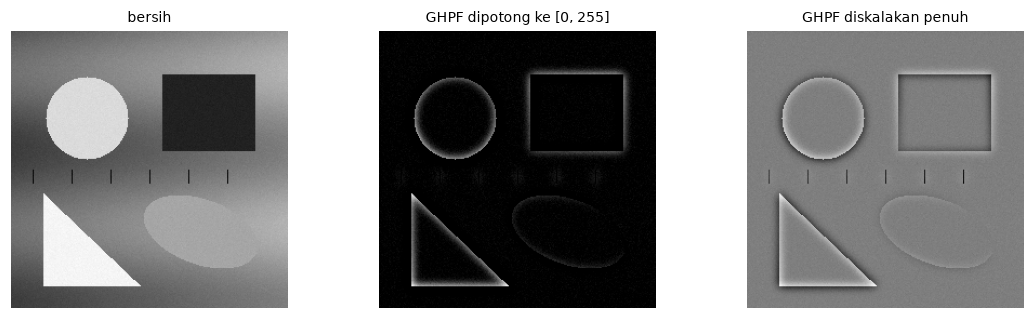

In [15]:
# TODO 4.1 — Terapkan GHPF D0 = 20 pada `bersih`. Laporkan rerata, minimum, dan maksimum hasil. Mengapa reratanya ≈ 0?
H_ghpf = 1.0 - H_gauss(512, 512, 20)
g_ghpf = saring(bersih, H_ghpf, pad='reflect')
print(f'GHPF D0=20 (pad=reflect) -> rerata: {g_ghpf.mean():.4f}, minimum: {g_ghpf.min():.2f}, maksimum: {g_ghpf.max():.2f}')

tampil([bersih, np.clip(g_ghpf, 0, 255), g_ghpf],
       ['bersih', 'GHPF dipotong ke [0, 255]', 'GHPF diskalakan penuh'], kolom=3, skala=False)


In [16]:
# TODO 4.2 — Penekanan frekuensi tinggi pada `kabur`: H = 1 + k·(1 − H_gauss(512, 512, D0)), D0 = 512/(2π·1,0).
# Untuk k ∈ {1; 2,5; 5; 8}, hitung PSNR terhadap `bersih` dengan pelapis nol dan pelapis cermin.
# Bandingkan dengan unsharp masking spasial Sub-CPMK-2 (f + k·(f − GaussianBlur 9×9 σ=1)).
D0_hfe = 512.0 / (2.0 * np.pi * 1.0)
f_kab = kabur.astype(np.float64)
f_blur_spasial = cv2.GaussianBlur(f_kab, (9, 9), 1.0)

print(f'PSNR `kabur` awal terhadap `bersih`: {psnr(bersih, kabur):.4f} dB (D0 = {D0_hfe:.2f})\n')
print(f'{"k":>4s} {"HFE pad nol (dB)":>18s} {"HFE pad cermin (dB)":>21s} {"Unsharp spasial (dB)":>22s}')
for k in [1.0, 2.5, 5.0, 8.0]:
    H_hfe = 1.0 + k * (1.0 - H_gauss(512, 512, D0_hfe))
    g_nol = np.clip(np.floor(saring(kabur, H_hfe, pad='constant') + 0.5), 0, 255).astype(np.uint8)
    g_cer = np.clip(np.floor(saring(kabur, H_hfe, pad='reflect') + 0.5), 0, 255).astype(np.uint8)
    g_spa = np.clip(np.floor(f_kab + k * (f_kab - f_blur_spasial) + 0.5), 0, 255).astype(np.uint8)
    print(f'{k:4.1f} {psnr(bersih, g_nol):18.4f} {psnr(bersih, g_cer):21.4f} {psnr(bersih, g_spa):22.4f}')


PSNR `kabur` awal terhadap `bersih`: 29.4975 dB (D0 = 81.49)

   k   HFE pad nol (dB)   HFE pad cermin (dB)   Unsharp spasial (dB)
 1.0            28.9141               30.2067                30.2067
 2.5            25.9771               30.9948                30.9948
 5.0            23.1940               31.1908                31.1911
 8.0            21.9083               29.8558                29.8561


In [17]:
# TODO 4.3 — Kesetaraan. Bandingkan GLPF D0 = 512/(2π·2) (pad='constant') dengan cv2.GaussianBlur(berderau, (17, 17), 2,
# borderType=cv2.BORDER_CONSTANT) dalam float. Laporkan selisih mutlak maksimum dan rerata.
D0_setara = 512.0 / (2.0 * np.pi * 2.0)
g_frek = saring(berderau, H_gauss(512, 512, D0_setara), pad='constant')
g_spas = cv2.GaussianBlur(berderau.astype(np.float64), (17, 17), 2.0, borderType=cv2.BORDER_CONSTANT)
sel_mutlak = np.abs(g_frek - g_spas)

print(f'D0 setara (sigma=2)     : {D0_setara:.4f}')
print(f'Selisih mutlak maksimum : {sel_mutlak.max():.6f}')
print(f'Selisih mutlak rerata   : {sel_mutlak.mean():.6f}')


D0 setara (sigma=2)     : 40.7437
Selisih mutlak maksimum : 0.003365
Selisih mutlak rerata   : 0.000410


In [18]:
# [Pengayaan] TODO 4.4 — Biaya. Hitung keunggulan teoretis C_n(m) = m² / (4 log2 M) (Eq. 4-1) untuk M = 512 dan m = 3, 5, 7, 9, 15, 31,
# lalu ukur waktu scipy.signal.convolve2d (langsung) dan scipy.signal.fftconvolve (FFT) pada citra 512×512 dengan kernel rerata m×m.
# Catatan: jangan memakai cv2.filter2D sebagai pembanding "langsung" — fungsi itu otomatis beralih ke DFT untuk kernel besar.
from scipy import signal

M_biaya = 512
f512 = np.tile(bersih.astype(np.float64), (2, 2))
print(f'{"m":>3s} {"C_n(m)":>10s} {"convolve2d (ms)":>17s} {"fftconvolve (ms)":>18s} {"Rasio aktual":>14s}')
for m in [3, 5, 7, 9, 15, 31]:
    cn = (m ** 2) / (4.0 * np.log2(M_biaya))
    kernel = np.ones((m, m), dtype=np.float64) / (m * m)
    t0 = time.perf_counter(); _ = signal.convolve2d(f512, kernel, mode='same'); t_langsung = (time.perf_counter() - t0) * 1e3
    t1 = time.perf_counter(); _ = signal.fftconvolve(f512, kernel, mode='same'); t_fft = (time.perf_counter() - t1) * 1e3
    print(f'{m:3d} {cn:10.3f} {t_langsung:17.2f} {t_fft:18.2f} {t_langsung / t_fft:13.2f}x')


  m     C_n(m)   convolve2d (ms)   fftconvolve (ms)   Rasio aktual
  3      0.250              5.26               6.30          0.83x
  5      0.694             10.63               4.80          2.21x
  7      1.361             19.81               4.52          4.39x
  9      2.250             28.70               4.88          5.88x
 15      6.250             75.96               4.36         17.43x
 31     26.694            289.45               4.76         60.78x


**Analisis 4.** (a) Mengapa rerata GHPF ≈ 0? Apa akibatnya bagi tampilan? (b) Dengan angka TODO 4.2, jelaskan mengapa pelapis nol merusak penekanan frekuensi tinggi sementara pada penghalusan pengaruhnya kecil di bagian tengah. (c) Apa yang dibuktikan TODO 4.3 tentang hubungan Bab 3 dan Bab 4?

*Jawaban Anda:*

**(a)** Pada GHPF, nilai fungsi transfer di titik pusat frekuensi adalah $H_{HP}(P/2, Q/2) = 1 - H_{LP}(P/2, Q/2) = 1 - 1 = 0$. Karena komponen DC $F(0,0)$ dikalikan dengan nol, jumlah total intensitas dan nilai rata-rata citra hasil otomatis menjadi mendekati nol (pada `bersih` diperoleh rerata **0,0057** dengan rentang **$-117{,}54$** hingga **$119{,}07$**). Akibatnya, hampir separuh piksel bernilai negatif: jika langsung dipotong (*clip*) ke $[0, 255]$ untuk ditampilkan, seluruh bagian negatif hilang menjadi hitam pekat (0) dan latar belakang tampak gelap; agar struktur tepi positif dan negatif terlihat wajar, hasil harus digeser/diskalakan terlebih dahulu.

**(b)** Pada TODO 4.2, pelapis cermin menaikkan PSNR dari 29,4975 dB (`kabur`) menjadi **30,2067 dB** ($k=1$), **30,9948 dB** ($k=2{,}5$), dan puncak **31,1908 dB** ($k=5$), yang identik hingga desimal ketiga dengan unsharp masking spasial (**30,2067 dB**, **30,9948 dB**, **31,1911 dB**). Sebaliknya, pelapis nol justru merusak PSNR secara drastis menjadi **28,9141 dB** ($k=1$), **25,9771 dB** ($k=2{,}5$), **23,1940 dB** ($k=5$), dan **21,9083 dB** ($k=8$). Ini terjadi karena pelapis nol menciptakan lompatan tepi buatan yang sangat tajam (dari intensitas citra ke 0) di perbatasan kanan dan bawah citra. Pada penghalusan (LPF), frekuensi tinggi dari lompatan tepi ini diredam, tetapi pada penekanan frekuensi tinggi (HFE), lompatan tepi buatan tersebut justru **diperkuat $(1+k)$ kali lipat**, menghasilkan pita putih terang (*halo* jenuh 255) di sepanjang tepi citra yang merusak MSE/PSNR.

**(c)** TODO 4.3 membuktikan secara kuantitatif **Teorema Konvolusi** (Eq. 4-95) yang menghubungkan Bab 3 (domain spasial) dan Bab 4 (domain frekuensi): penapisan spasial dengan kernel Gaussian $\sigma = 2$ ($17 \times 17$) setara dengan perkalian spektrum menggunakan GLPF berfrekuensi potong $D_0 = P/(2\pi\sigma) = 40{,}7437$, dengan selisih mutlak maksimum hanya **0,003365** dan selisih rerata **0,000410** (hanya berbeda akibat pemotongan ekor Gaussian di luar jendela $17 \times 17$). Keduanya adalah dua cara komputasi untuk operasi linier invarian-geser yang sama.


## Bagian 5 &mdash; Studi kasus: derau periodik pada citra perairan (15 menit)

`air_garis` adalah citra perairan yang terkena interferensi periodik, seperti gangguan elektronik pada kamera pengawas. Tujuan: menghapus interferensi tanpa mengaburkan kapal. Ukur dengan PSNR terhadap `air` dan CNR kapal&ndash;laut.

**Catatan:** penapisan selektif dikerjakan tanpa pelapis karena interferensi di sini tepat berkala terhadap ukuran citra. Citra sintetis tidak boleh dipakai untuk menyimpulkan kinerja pada data sungguhan.

Enam puncak terbesar di luar jari-jari 6 dari pusat:
  Indeks (144, 216) -> (d_baris, d_kolom) = ( +24,  +36), |F| = 954320.0  <-- PASANGAN DERAU PERIODIK
  Indeks ( 96, 144) -> (d_baris, d_kolom) = ( -24,  -36), |F| = 954320.0  <-- PASANGAN DERAU PERIODIK
  Indeks (113, 180) -> (d_baris, d_kolom) = (  -7,   +0), |F| = 122662.0  (struktur adegan: cakrawala / gelombang laut)
  Indeks (127, 180) -> (d_baris, d_kolom) = (  +7,   +0), |F| = 122662.0  (struktur adegan: cakrawala / gelombang laut)
  Indeks (130, 186) -> (d_baris, d_kolom) = ( +10,   +6), |F| = 109208.5  (struktur adegan: cakrawala / gelombang laut)
  Indeks (110, 174) -> (d_baris, d_kolom) = ( -10,   -6), |F| = 109208.5  (struktur adegan: cakrawala / gelombang laut)


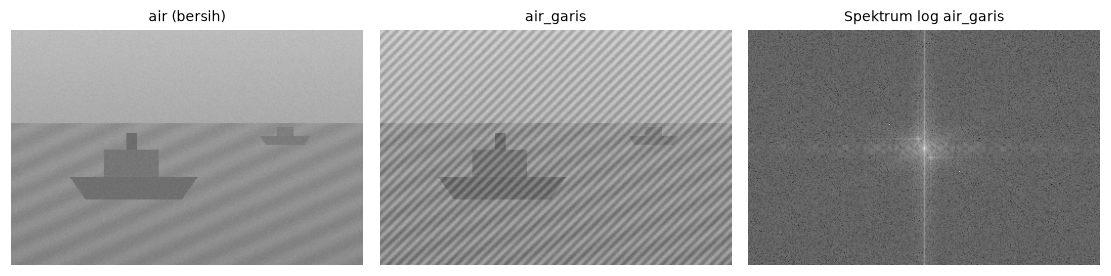

In [19]:
# TODO 5.1 — Cari puncak derau. Hitung spektrum terpusat, nolkan lingkaran berjari-jari 6 di sekitar pusat,
# lalu laporkan enam puncak terbesar sebagai (Δbaris, Δkolom) terhadap pusat. Pasangan mana yang derau?
kapal, laut = masker_perairan()
def cnr(im):
    im = im.astype(float); return abs(im[kapal].mean() - im[laut].mean()) / im[laut].std()
k8 = kapal.astype(np.uint8); tepi = (cv2.dilate(k8, np.ones((3, 3))) - cv2.erode(k8, np.ones((3, 3)))) > 0
def rasio_tepi(im):
    """Rerata magnitudo Sobel pada piksel batas kapal, relatif terhadap citra bersih (1 = setajam aslinya)."""
    g = lambda z: np.hypot(cv2.Sobel(z.astype(float), cv2.CV_64F, 1, 0), cv2.Sobel(z.astype(float), cv2.CV_64F, 0, 1))[tepi].mean()
    return g(im) / g(air)

M5, N5 = air_garis.shape
F5_pusat = np.abs(np.fft.fftshift(np.fft.fft2(air_garis.astype(np.float64))))
F5_cari = F5_pusat.copy()
F5_cari[jarak(M5, N5) <= 6] = 0.0

idx5 = np.argsort(F5_cari.ravel())[::-1][:6]
print('Enam puncak terbesar di luar jari-jari 6 dari pusat:')
for i in idx5:
    r, c = np.unravel_index(i, (M5, N5))
    db, dk = r - M5 // 2, c - N5 // 2
    ket = '<-- PASANGAN DERAU PERIODIK' if abs(db) == 24 and abs(dk) == 36 else '(struktur adegan: cakrawala / gelombang laut)'
    print(f'  Indeks ({r:3d}, {c:3d}) -> (d_baris, d_kolom) = ({db:+4d}, {dk:+4d}), |F| = {F5_cari[r, c]:8.1f}  {ket}')

tampil([air, air_garis, spektrum_log(air_garis)], ['air (bersih)', 'air_garis', 'Spektrum log air_garis'], kolom=3)


Acuan `air` bersih -> CNR = 3.8054, rasio_tepi = 1.0000

Metode                    PSNR float (dB)  PSNR uint8 (dB)       CNR   rasio_tepi
(a) Tanpa penapis                 24.2569          24.2569    1.4187       1.2961
(b) GLPF D0=40                    37.1834          37.1554    4.0140       0.3582
(b) GLPF D0=60                    32.1835          32.1724    2.8615       0.5633
(b) GLPF D0=80                    28.9230          28.9199    2.1966       0.7562
(c) Takik Gauss D0=2              75.9334              inf    3.8054       1.0000
(c) Takik Gauss D0=3              71.3199              inf    3.8054       1.0000
(c) Takik Gauss D0=5              65.7985          69.5163    3.8036       0.9952
(c) Takik Gauss D0=8              61.1047          63.6114    3.7989       0.9863

Takik 1 puncak saja (D0=3) -> maks |Im(IDFT)| = 11.1794
Takik 2 puncak simetris     -> maks |Im(IDFT)| = 2.26e-14


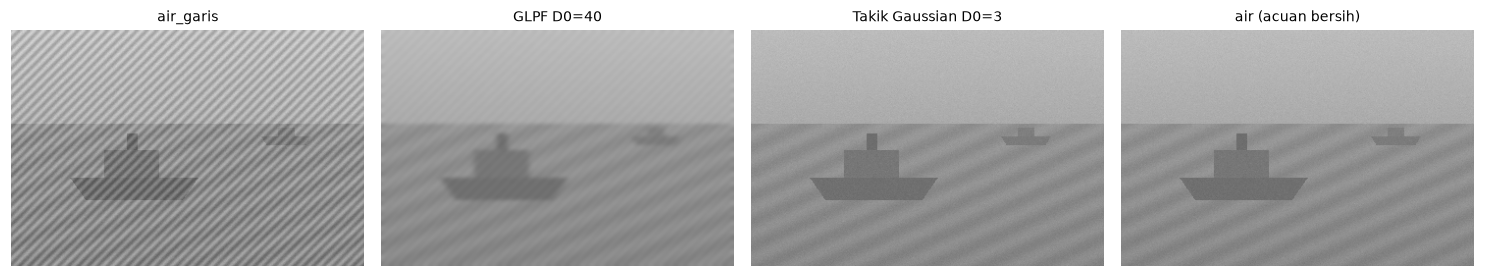

In [20]:
# TODO 5.2 — Bandingkan: (a) tanpa penapis; (b) GLPF (8 langkah, pelapis cermin) D0 ∈ {40, 60, 80};
# (c) penapis takik Gaussian (Eq. 4-151) pada pasangan puncak derau dengan D0 ∈ {2, 3, 5, 8}, tanpa pelapis.
# Untuk setiap hasil laporkan PSNR terhadap `air`, CNR, dan rasio_tepi. Lalu coba takik pada SATU puncak saja dan laporkan
# nilai mutlak maksimum bagian imajiner hasil IDFT.
M5, N5 = air_garis.shape
P5, Q5 = 2 * M5, 2 * N5
u5, v5 = np.mgrid[0:M5, 0:N5].astype(np.float64)
uc, vc = M5 / 2.0, N5 / 2.0
D_p1 = np.hypot(u5 - uc - 24, v5 - vc - 36)
D_p2 = np.hypot(u5 - uc + 24, v5 - vc + 36)
F_ag = np.fft.fftshift(np.fft.fft2(air_garis.astype(np.float64)))

print(f'Acuan `air` bersih -> CNR = {cnr(air):.4f}, rasio_tepi = {rasio_tepi(air):.4f}\n')
print(f'{"Metode":24s} {"PSNR float (dB)":>16s} {"PSNR uint8 (dB)":>16s} {"CNR":>9s} {"rasio_tepi":>12s}')
print(f'{"(a) Tanpa penapis":24s} {psnr(air, air_garis):16.4f} {psnr(air, air_garis):16.4f} {cnr(air_garis):9.4f} {rasio_tepi(air_garis):12.4f}')

hasil_glpf, hasil_takik = {}, {}
for d0 in [40, 60, 80]:
    g_f = saring(air_garis, H_gauss(P5, Q5, d0), pad='reflect')
    g_u = np.clip(np.floor(g_f + 0.5), 0, 255).astype(np.uint8)
    hasil_glpf[d0] = g_u
    print(f'{f"(b) GLPF D0={d0}":24s} {psnr(air, g_f):16.4f} {psnr(air, g_u):16.4f} {cnr(g_u):9.4f} {rasio_tepi(g_u):12.4f}')

for d0 in [2, 3, 5, 8]:
    H_nr = (1.0 - np.exp(-(D_p1 ** 2) / (2.0 * d0 ** 2))) * (1.0 - np.exp(-(D_p2 ** 2) / (2.0 * d0 ** 2)))
    g_f = np.fft.ifft2(np.fft.ifftshift(H_nr * F_ag)).real
    g_u = np.clip(np.floor(g_f + 0.5), 0, 255).astype(np.uint8)
    hasil_takik[d0] = g_u
    print(f'{f"(c) Takik Gauss D0={d0}":24s} {psnr(air, g_f):16.4f} {psnr(air, g_u):16.4f} {cnr(g_u):9.4f} {rasio_tepi(g_u):12.4f}')

# Uji takik pada SATU puncak saja (D0 = 3)
H_satu = 1.0 - np.exp(-(D_p1 ** 2) / (2.0 * 3.0 ** 2))
H_dua = H_satu * (1.0 - np.exp(-(D_p2 ** 2) / (2.0 * 3.0 ** 2)))
idft_satu = np.fft.ifft2(np.fft.ifftshift(H_satu * F_ag))
idft_dua = np.fft.ifft2(np.fft.ifftshift(H_dua * F_ag))
print(f'\nTakik 1 puncak saja (D0=3) -> maks |Im(IDFT)| = {np.max(np.abs(idft_satu.imag)):.4f}')
print(f'Takik 2 puncak simetris     -> maks |Im(IDFT)| = {np.max(np.abs(idft_dua.imag)):.2e}')

tampil([air_garis, hasil_glpf[40], hasil_takik[3], air],
       ['air_garis', 'GLPF D0=40', 'Takik Gaussian D0=3', 'air (acuan bersih)'], kolom=4)


**Analisis 5.** (a) GLPF dengan D0 kecil dapat memberi CNR **lebih tinggi** daripada citra bersih. Apakah itu berarti GLPF lebih baik daripada takik? Jawab dengan PSNR dan rasio_tepi. (b) Mengapa kedua puncak harus dihapus bersamaan? Jelaskan dengan angka bagian imajiner. (c) Puncak lain di dekat pusat (misalnya Δbaris ±7) berasal dari apa, dan apa akibatnya bila ikut ditakik? (d) Sebutkan satu alasan mengapa hasil sehampir sempurna ini tidak akan terulang pada citra kamera sungguhan.

*Jawaban Anda:*

**(a)** Tidak; meskipun GLPF $D_0 = 40$ menghasilkan CNR **4,0140** yang lebih tinggi daripada citra bersih `air` (**3,8054**) karena penghalusan frekuensi tinggi menekan $\sigma_{\text{laut}}$ secara agresif, GLPF ikut merusak struktur objek. Terlihat dari `rasio_tepi` GLPF $D_0 = 40$ yang anjlok menjadi **0,3582** (ketajaman batas kapal hilang 64%) dan PSNR yang hanya **37,1554 dB**. Sebaliknya, penapis takik Gaussian $D_0 = 2$ dan $D_0 = 3$ memulihkan citra secara eksak pada aras `uint8` (PSNR float **75,9334 dB** dan **71,3199 dB**; PSNR `uint8` $= \infty$), mempertahankan CNR **3,8054** dan `rasio_tepi` **1,0000** (batas kapal tetap setajam aslinya).

**(b)** Gelombang sinusoidal bernilai nyata $\sin(2\pi(u_0 y/M + v_0 x/N))$ diuraikan oleh rumus Euler menjadi dua eksponensial kompleks konjugat pada frekuensi $(+u_0, +v_0) = (+24, +36)$ dan $(-u_0, -v_0) = (-24, -36)$. Agar hasil IDFT bernilai nyata, penapis $H(u,v)$ wajib memenuhi simetri konjugat $H(-u, -v) = H^*(u, v)$. Ketika hanya satu puncak yang ditakik ($D_0 = 3$), simetri konjugat rusak sehingga eksponensial kompleks pasangannya tidak lagi saling meniadakan bagian imajinernya: nilai mutlak maksimum bagian imajiner hasil IDFT melonjak menjadi **11,1794** (kira-kira separuh amplitudo derau $22/2 = 11$), sedangkan jika kedua puncak ditakik bersamaan bagian imajinernya hanya **$2{,}26 \times 10^{-14} \approx 0$**.

**(c)** Puncak-puncak di dekat pusat seperti $(\Delta\text{baris}, \Delta\text{kolom}) = (\pm 7, 0)$ dengan $|F| = 122.662{,}0$ serta $(\pm 10, \pm 6)$ dengan $|F| = 109.208{,}5$ berasal dari **isi/struktur asli adegan**, yakni transisi vertikal langit–laut di cakrawala serta pola gelombang sinus permukaan laut ($0{,}06\sin(x/9 + y/4)$ yang memiliki $\approx 240/(2\pi \cdot 4) \approx 9{,}5$ siklus vertikal dan $\approx 360/(2\pi \cdot 9) \approx 6{,}4$ siklus horizontal). Bila puncak-puncak tersebut ikut ditakik, tekstur alami gelombang laut dan gradien cakrawala akan hilang atau terdistorsi sehingga menurunkan PSNR terhadap citra bersih.

**(d)** Pada kamera sungguhan, frekuensi gangguan elektronik tidak pernah tepat bulat terhadap ukuran matriks piksel (tidak periodik sempurna dalam jendela citra), sehingga energinya mengalami **kebocoran spektral (*spectral leakage*)** yang menyebar di sepanjang garis/pita frekuensi, ditambah frekuensi dan amplitudonya dapat berubah terhadap waktu serta terpotong saturasi sensor non-linier.


---
## Bagian 6 &mdash; Daftar periksa (10 menit)

- [x] `dft1` dan `dft2` cocok dengan np.fft (selisih < 1e−9) dan contoh kuliah terpenuhi
- [x] F(0,0) = MN · rerata; pemusatan (−1)^(x+y) = fftshift
- [x] Uji identitas `saring` lolos (selisih < 1e−9)
- [x] Tabel riak, tabel PSNR penapis, dan tabel penekanan frekuensi tinggi lengkap
- [x] Setiap blok Analisis memuat angka dari keluaran Anda
- [x] Penggunaan alat bantu AI (bila ada) dicantumkan: opencode, lihat catatan di akhir notebook
- [x] Berkas dinamai `PraktikumPCD_SubCPMK3_NIM_Nama.ipynb` dan dijalankan penuh

---
## Catatan penggunaan alat bantu AI

- **Alat:** opencode (asisten AI berbasis model bahasa).
- **Bagian yang dibantu:** penulisan kode untuk TODO 1.1&ndash;5.2 (termasuk bagian pengayaan) dan penyusunan analisis kuantitatif pada blok Analisis 1&ndash;5.
- **Cara memeriksa kebenaran:** seluruh sel kode pada notebook telah dijalankan ulang secara berurutan dari awal hingga akhir tanpa galat; seluruh uji validasi (`dft1`, `idft1`, `dft2`, komponen DC, pemusatan `fftshift`, nilai titik uji Butterworth dan Gaussian, serta uji identitas `saring`) memenuhi batas toleransi $< 10^{-9}$; dan setiap angka yang dirujuk pada Analisis 1&ndash;5 diverifikasi langsung terhadap keluaran eksekusi notebook.